# Write a python program to add artificial noise (Salt and Pepper, Gaussian) and restore images.

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [13]:
img = cv2.imread("image.jpeg", cv2.IMREAD_GRAYSCALE)
row, col = img.shape

In [14]:
salt_pepper_img = img.copy()
for i in range(row):
    for j in range(col):
        r = np.random.rand()
        if r < 0.02:
            salt_pepper_img[i, j] = 0
        elif r > .98:
            salt_pepper_img[i, j] = 255

In [15]:
noise = np.random.normal(0, 20, img.shape)
gaussian_noise_img = np.add(img, noise)
gaussian_noise_img = np.clip(gaussian_noise_img, 0, 255)

In [16]:
# Remove salt pepper noise using median filter
median_img = np.zeros(img.shape)
for i in range(1, row - 1):
    for j in range(1, col - 1):
        matrix = salt_pepper_img[i-1:i+2, j-1:j+2]
        median_img[i, j] = np.median(matrix)

In [17]:
gaussian_filter = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
]) / 16

gaussian_filter_img = np.zeros(img.shape)

for i in range(1, row - 1):
    for j in range(1, col - 1):
        matrix = gaussian_noise_img[i-1:i+2, j-1:j+2]
        gaussian_filter_img[i, j] = np.sum(matrix * gaussian_filter)

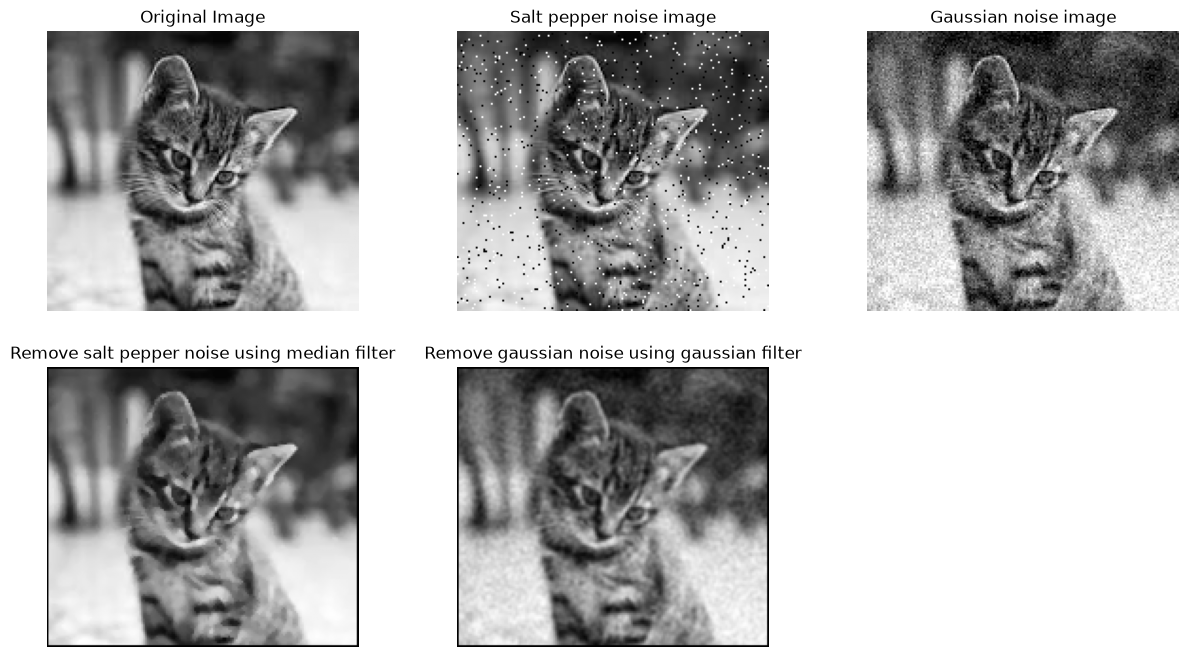

In [18]:
imgs = [img, salt_pepper_img, gaussian_noise_img, median_img, gaussian_filter_img]
title = ["Original Image", "Salt pepper noise image", "Gaussian noise image", "Remove salt pepper noise using median filter", "Remove gaussian noise using gaussian filter"]

plt.figure(figsize=(15, 8))
for i in range(5):
    plt.subplot(2, 3, i + 1)
    plt.imshow(imgs[i], cmap="gray")
    plt.title(title[i])
    plt.axis("off")